# Resume Screening Tool

PROJECT_TITLE : "Resume Screening Tool"

PROJECT_OBJECTIVE : 
Build an intelligent resume screening system that:
1. Extracts useful information from resumes.
2. Processes resume and job-description text using NLP.
3. Identifies skills, education and experience.
4. Predicts resume-job relevance using an LSTM/BiLSTM model.
5. Calculates a transparent job-specific match score.
6. Ranks candidates.
7. Uses Generative AI to generate candidate summaries,
   strengths, gaps and interview-question suggestions.


PREDICTION_TASK : "Strong Match / Moderate Match / Weak Match"

PROJECT PIPELINE
1. Resume Upload
2. Text Extraction
3. NLP Preprocessing
4. Information Extraction
5. Job Description Processing
6. Feature Engineering
7. TF-IDF Baseline
8. LSTM/BiLSTM Model
9. Resume-Job Matching
10. Candidate Ranking
11. Generative AI Explanation
12. Streamlit Application
13. Evaluation

EVALUATION_METRICS 
- Accuracy
- Precision
- Recall
- F1-Score
- Confusion Matrix
- ROC-AUC / PR-AUC
- Ranking Performance

In [1]:
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv(r'C:\Users\S. Umredkar\Desktop\Data Science IPCS Global\Resume screening Tool\Dataset\Resume\Resume.csv')
df.shape

(2484, 4)

In [3]:
print('Columns:',df.columns.tolist())
df.head()

Columns: ['ID', 'Resume_str', 'Resume_html', 'Category']


,ID,Resume_str,Resume_html,Category
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,"<div class=""fontsize fontface vmargins hmargin...",HR
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...","<div class=""fontsize fontface vmargins hmargin...",HR
2,33176873,HR DIRECTOR Summary Over 2...,"<div class=""fontsize fontface vmargins hmargin...",HR
3,27018550,HR SPECIALIST Summary Dedica...,"<div class=""fontsize fontface vmargins hmargin...",HR
4,17812897,HR MANAGER Skill Highlights ...,"<div class=""fontsize fontface vmargins hmargin...",HR


In [4]:
print(df.info())
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2484 entries, 0 to 2483
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   ID           2484 non-null   int64 
 1   Resume_str   2484 non-null   object
 2   Resume_html  2484 non-null   object
 3   Category     2484 non-null   object
dtypes: int64(1), object(3)
memory usage: 77.8+ KB
None
ID             0
Resume_str     0
Resume_html    0
Category       0
dtype: int64


In [5]:
print(df.duplicated().sum())
print(df['ID'].duplicated().sum())
print(df['Resume_str'].duplicated().sum())

0
0
2


In [6]:
print(df[df['Resume_str'].duplicated(keep=False)])
df = df.drop_duplicates(subset="Resume_str", keep="first").copy()
print(df['Resume_str'].duplicated().sum())

            ID                                         Resume_str  \
1490  19147603           FINANCE OFFICER         Professional ...   
1509  28398216           FINANCE OFFICER         Professional ...   
2444  16850314           STOREKEEPER II       Professional Sum...   
2483  37473139           STOREKEEPER II       Professional Sum...   

                                            Resume_html  Category  
1490  <div class="fontsize fontface vmargins hmargin...   FINANCE  
1509  <div class="fontsize fontface vmargins hmargin...   FINANCE  
2444  <div class="fontsize fontface vmargins hmargin...  AVIATION  
2483  <div class="fontsize fontface vmargins hmargin...  AVIATION  
0


In [7]:
print('Number of categories:',df['Category'].nunique())
print(df['Category'].value_counts())

Number of categories: 24
Category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      120
ADVOCATE                  118
CHEF                      118
ENGINEERING               118
ACCOUNTANT                118
FINANCE                   117
FITNESS                   117
SALES                     116
AVIATION                  116
BANKING                   115
HEALTHCARE                115
CONSULTANT                115
CONSTRUCTION              112
PUBLIC-RELATIONS          111
HR                        110
DESIGNER                  107
ARTS                      103
TEACHER                   102
APPAREL                    97
DIGITAL-MEDIA              96
AGRICULTURE                63
AUTOMOBILE                 36
BPO                        22
Name: count, dtype: int64


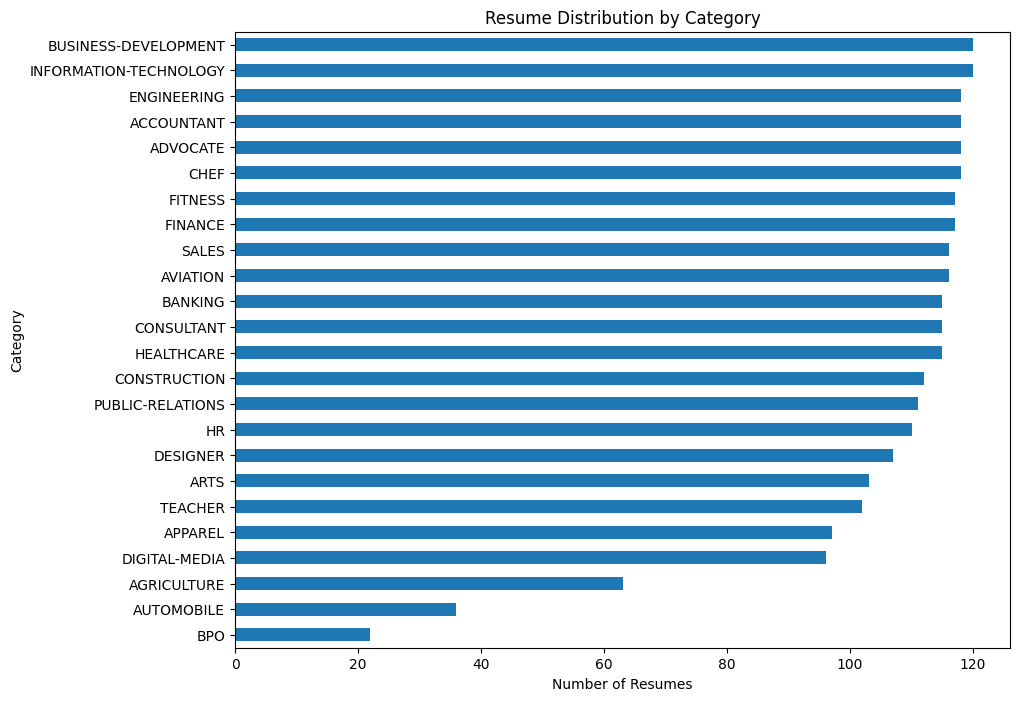

In [8]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,8))
df['Category'].value_counts().sort_values().plot(kind='barh')
plt.title("Resume Distribution by Category")
plt.xlabel("Number of Resumes")
plt.ylabel("Category")
plt.show()

count     2482.000000
mean      6296.179291
std       2770.197425
min         21.000000
25%       5160.000000
50%       5887.500000
75%       7227.750000
max      38842.000000
Name: Resume_Length, dtype: float64


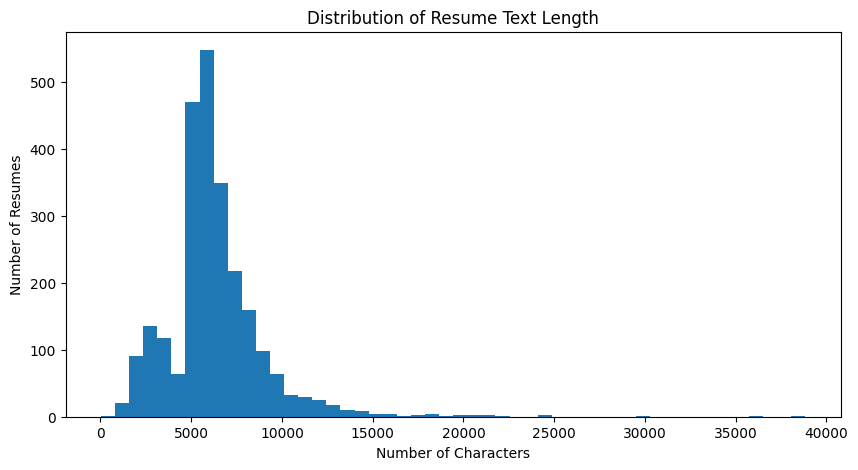

In [9]:
df["Resume_Length"] = df["Resume_str"].str.len()
print(df["Resume_Length"].describe())
plt.figure(figsize=(10, 5))
plt.hist(df["Resume_Length"], bins=50)
plt.title("Distribution of Resume Text Length")
plt.xlabel("Number of Characters")
plt.ylabel("Number of Resumes")
plt.show()

In [10]:
short_resumes = df[df["Resume_str"].str.len() < 500]
print("Number of resumes shorter than 500 characters:",
      len(short_resumes))
short_resumes

Number of resumes shorter than 500 characters: 1


,ID,Resume_str,Resume_html,Category,Resume_Length
656,12632728,,"<div class=""fontsize fontface vmargins hmargin...",BUSINESS-DEVELOPMENT,21


In [11]:
# Remove the problematic resume
df = df[df["Resume_str"].str.len() >= 500].copy()
print("Dataset shape:", df.shape)
print("Minimum resume length:", df["Resume_str"].str.len().min())

Dataset shape: (2481, 5)
Minimum resume length: 881


In [12]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate Resume_str:")
print(df["Resume_str"].duplicated().sum())

print("\nCategories:")
print(df["Category"].nunique())

Shape: (2481, 5)

Columns:
['ID', 'Resume_str', 'Resume_html', 'Category', 'Resume_Length']

Missing values:
ID               0
Resume_str       0
Resume_html      0
Category         0
Resume_Length    0
dtype: int64

Duplicate Resume_str:
0

Categories:
24


In [13]:
df = df.drop(columns=["Resume_Length"])
print(df.shape)
print(df.columns.tolist())

(2481, 4)
['ID', 'Resume_str', 'Resume_html', 'Category']


In [14]:
clean_path = r"C:\Users\S. Umredkar\Desktop\Data Science IPCS Global\Resume screening Tool\Dataset\Resume\Resume_cleaned.csv"
df.to_csv(clean_path, index=False)

In [15]:
sample_resume = df.loc[0, "Resume_str"]
print(sample_resume)

         HR ADMINISTRATOR/MARKETING ASSOCIATE

HR ADMINISTRATOR       Summary     Dedicated Customer Service Manager with 15+ years of experience in Hospitality and Customer Service Management.   Respected builder and leader of customer-focused teams; strives to instill a shared, enthusiastic commitment to customer service.         Highlights         Focused on customer satisfaction  Team management  Marketing savvy  Conflict resolution techniques     Training and development  Skilled multi-tasker  Client relations specialist           Accomplishments      Missouri DOT Supervisor Training Certification  Certified by IHG in Customer Loyalty and Marketing by Segment   Hilton Worldwide General Manager Training Certification  Accomplished Trainer for cross server hospitality systems such as    Hilton OnQ  ,   Micros    Opera PMS   , Fidelio    OPERA    Reservation System (ORS) ,   Holidex    Completed courses and seminars in customer service, sales strategies, inventory control, loss preve

In [16]:
print("Characters:", len(sample_resume))
print("Words:", len(sample_resume.split()))

Characters: 5442
Words: 674


In [17]:
import re
from bs4 import BeautifulSoup

def clean_resume_text(text):
    """
    Clean resume text while preserving important
    technical terms and domain-specific information.
    """
    
    # Convert to string
    text = str(text)
    
    # Remove HTML tags if any exist
    text = BeautifulSoup(text, "html.parser").get_text(" ")
    
    # Replace line breaks and tabs with spaces
    text = re.sub(r"[\r\n\t]+", " ", text)
    
    # Remove non-printable characters
    text = "".join(
        char for char in text
        if char.isprintable()
    )
    
    # Normalize multiple spaces
    text = re.sub(r"\s+", " ", text)
    
    # Remove spaces before common punctuation
    text = re.sub(r"\s+([,.;:])", r"\1", text)
    
    # Remove leading/trailing whitespace
    text = text.strip()
    
    return text

In [18]:
cleaned_sample = clean_resume_text(sample_resume)

print("CLEANED RESUME")
print("=" * 80)
print(cleaned_sample)

CLEANED RESUME
HR ADMINISTRATOR/MARKETING ASSOCIATE HR ADMINISTRATOR Summary Dedicated Customer Service Manager with 15+ years of experience in Hospitality and Customer Service Management. Respected builder and leader of customer-focused teams; strives to instill a shared, enthusiastic commitment to customer service. Highlights Focused on customer satisfaction Team management Marketing savvy Conflict resolution techniques Training and development Skilled multi-tasker Client relations specialist Accomplishments Missouri DOT Supervisor Training Certification Certified by IHG in Customer Loyalty and Marketing by Segment Hilton Worldwide General Manager Training Certification Accomplished Trainer for cross server hospitality systems such as Hilton OnQ, Micros Opera PMS, Fidelio OPERA Reservation System (ORS), Holidex Completed courses and seminars in customer service, sales strategies, inventory control, loss prevention, safety, time management, leadership and performance assessment. Exper

In [19]:
comparison = pd.DataFrame({
    "Version": ["Original", "Cleaned"],
    "Characters": [
        len(sample_resume),
        len(cleaned_sample)
    ],
    "Words": [
        len(sample_resume.split()),
        len(cleaned_sample.split())
    ]
})

display(comparison)

,Version,Characters,Words
0,Original,5442,674
1,Cleaned,5013,660


In [20]:
df["Cleaned_Resume"] = df["Resume_str"].apply(clean_resume_text)
print("Cleaning completed!")
print("Number of resumes:", len(df))

Cleaning completed!
Number of resumes: 2481


In [21]:
empty_cleaned = df["Cleaned_Resume"].str.strip().eq("").sum()
print("Empty cleaned resumes:", empty_cleaned)

Empty cleaned resumes: 0


In [22]:
cleaned_lengths = df["Cleaned_Resume"].str.len()
print(cleaned_lengths.describe())

count     2481.000000
mean      5918.854897
std       2682.091228
min        682.000000
25%       4804.000000
50%       5532.000000
75%       6831.000000
max      35209.000000
Name: Cleaned_Resume, dtype: float64


In [23]:
clean_path = r"C:\Users\S. Umredkar\Desktop\Data Science IPCS Global\Resume screening Tool\Dataset\Resume\Resume_cleaned.csv"
df.to_csv(clean_path, index=False)
print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [24]:
import nltk
nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt to C:\Users\S.
[nltk_data]     Umredkar\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to C:\Users\S.
[nltk_data]     Umredkar\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [25]:
from nltk.tokenize import word_tokenize
print("NLTK tokenizer ready!")

NLTK tokenizer ready!


In [26]:
sample_cleaned = df.loc[0, "Cleaned_Resume"]
tokens = word_tokenize(sample_cleaned)
print("First 100 tokens:")
print(tokens[:100])
print("\nTotal tokens:", len(tokens))

First 100 tokens:
['HR', 'ADMINISTRATOR/MARKETING', 'ASSOCIATE', 'HR', 'ADMINISTRATOR', 'Summary', 'Dedicated', 'Customer', 'Service', 'Manager', 'with', '15+', 'years', 'of', 'experience', 'in', 'Hospitality', 'and', 'Customer', 'Service', 'Management', '.', 'Respected', 'builder', 'and', 'leader', 'of', 'customer-focused', 'teams', ';', 'strives', 'to', 'instill', 'a', 'shared', ',', 'enthusiastic', 'commitment', 'to', 'customer', 'service', '.', 'Highlights', 'Focused', 'on', 'customer', 'satisfaction', 'Team', 'management', 'Marketing', 'savvy', 'Conflict', 'resolution', 'techniques', 'Training', 'and', 'development', 'Skilled', 'multi-tasker', 'Client', 'relations', 'specialist', 'Accomplishments', 'Missouri', 'DOT', 'Supervisor', 'Training', 'Certification', 'Certified', 'by', 'IHG', 'in', 'Customer', 'Loyalty', 'and', 'Marketing', 'by', 'Segment', 'Hilton', 'Worldwide', 'General', 'Manager', 'Training', 'Certification', 'Accomplished', 'Trainer', 'for', 'cross', 'server', 'hospi

In [27]:
print("Original words:", len(sample_cleaned.split()))
print("NLTK tokens:", len(tokens))

Original words: 660
NLTK tokens: 787


In [28]:
from sklearn.feature_extraction.text import TfidfVectorizer
print("TF-IDF library ready!")

TF-IDF library ready!


In [29]:
tfidf_vectorizer = TfidfVectorizer(
    lowercase=True,
    max_features=5000,
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.95,
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z0-9+#.-]*\b"
)
tfidf_matrix = tfidf_vectorizer.fit_transform(df["Cleaned_Resume"])
feature_names = tfidf_vectorizer.get_feature_names_out()
print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Number of features:", len(feature_names))

TF-IDF matrix shape: (2481, 5000)
Number of features: 5000


In [30]:
feature_names = tfidf_vectorizer.get_feature_names_out()
print("Number of features:", len(feature_names))
print("\nFirst 100 features:")
print(feature_names[:100])

Number of features: 5000

First 100 features:
['a clean' 'a company' 'a comprehensive' 'a daily' 'a fast' 'a high'
 'a increase' 'a key' 'a large' 'a liaison' 'a member' 'a million'
 'a monthly' 'a new' 'a p' 'a position' 'a positive' 'a professional'
 'a r' 'a safe' 'a staff' 'a strong' 'a successful' 'a team' 'a timely'
 'a variety' 'a weekly' 'a wide' 'a year' 'abilities' 'ability'
 'ability to' 'able' 'able to' 'about' 'about the' 'above' 'absence'
 'abuse' 'academic' 'academy' 'acceptance' 'accepted' 'access'
 'access excel' 'access to' 'accessories' 'accommodate' 'accomplish'
 'accomplished' 'accomplishments' 'accordance' 'accordance with'
 'according' 'according to' 'accordingly' 'account' 'account executive'
 'account management' 'account manager' 'account reconciliation'
 'account reconciliations' 'accountability' 'accountable'
 'accountable for' 'accountant' 'accountant company' 'accounting'
 'accounting and' 'accounting software' 'accounting system' 'accounts'
 'accounts and

In [31]:
print("Rows (resumes):", tfidf_matrix.shape[0])
print("Columns (features):", tfidf_matrix.shape[1])
print("Matrix type:", type(tfidf_matrix))

Rows (resumes): 2481
Columns (features): 5000
Matrix type: <class 'scipy.sparse._csr.csr_matrix'>


-----------------Classification--------------

In [32]:
X = tfidf_matrix
y = df["Category"]
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (2481, 5000)
y shape: (2481,)


In [33]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 1984
Testing samples: 497


In [34]:
from sklearn.linear_model import LogisticRegression
baseline_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)
baseline_model.fit(X_train, y_train)
print("Baseline model trained successfully!")

Baseline model trained successfully!


In [35]:
y_pred = baseline_model.predict(X_test)
print("Predictions generated!")
print("Number of predictions:", len(y_pred))

Predictions generated!
Number of predictions: 497


In [36]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)
print(f"Baseline Accuracy: {accuracy:.4f}")
print(f"Baseline Accuracy: {accuracy * 100:.2f}%")

Baseline Accuracy: 0.6579
Baseline Accuracy: 65.79%


In [37]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred,zero_division=0))

                        precision    recall  f1-score   support

            ACCOUNTANT       0.57      0.83      0.68        24
              ADVOCATE       0.38      0.58      0.46        24
           AGRICULTURE       1.00      0.38      0.56        13
               APPAREL       0.60      0.16      0.25        19
                  ARTS       0.50      0.38      0.43        21
            AUTOMOBILE       0.00      0.00      0.00         7
              AVIATION       0.81      0.74      0.77        23
               BANKING       0.83      0.65      0.73        23
                   BPO       0.00      0.00      0.00         4
  BUSINESS-DEVELOPMENT       0.55      0.92      0.69        24
                  CHEF       0.85      0.71      0.77        24
          CONSTRUCTION       0.85      0.77      0.81        22
            CONSULTANT       0.45      0.22      0.29        23
              DESIGNER       0.84      0.76      0.80        21
         DIGITAL-MEDIA       0.71      

-----------LSTM----------

In [38]:
from sklearn.model_selection import train_test_split
X_text = df["Cleaned_Resume"]
y = df["Category"]
X_train_text, X_test_text, y_train, y_test = train_test_split(X_text,y,test_size=0.20,random_state=42,stratify=y)
print("Training resumes:", len(X_train_text))
print("Testing resumes:", len(X_test_text))

Training resumes: 1984
Testing resumes: 497


In [39]:
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)
print("Number of classes:", len(label_encoder.classes_))
print("\nClasses:")
print(label_encoder.classes_)

Number of classes: 24

Classes:
['ACCOUNTANT' 'ADVOCATE' 'AGRICULTURE' 'APPAREL' 'ARTS' 'AUTOMOBILE'
 'AVIATION' 'BANKING' 'BPO' 'BUSINESS-DEVELOPMENT' 'CHEF' 'CONSTRUCTION'
 'CONSULTANT' 'DESIGNER' 'DIGITAL-MEDIA' 'ENGINEERING' 'FINANCE' 'FITNESS'
 'HEALTHCARE' 'HR' 'INFORMATION-TECHNOLOGY' 'PUBLIC-RELATIONS' 'SALES'
 'TEACHER']


In [40]:
from tensorflow.keras.preprocessing.text import Tokenizer
MAX_WORDS = 10000
tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)
tokenizer.fit_on_texts(X_train_text)
print("Vocabulary size:", len(tokenizer.word_index))

Vocabulary size: 38779


In [41]:
X_train_sequences = tokenizer.texts_to_sequences(X_train_text)
X_test_sequences = tokenizer.texts_to_sequences(X_test_text)

print("First training sequence:")
print(X_train_sequences[0][:50])

print("\nNumber of training sequences:", len(X_train_sequences))
print("Number of testing sequences:", len(X_test_sequences))

First training sequence:
[226, 1059, 679, 6, 147, 2885, 146, 131, 205, 884, 4167, 125, 7, 1753, 42, 115, 6, 399, 114, 1, 7, 2885, 2, 146, 131, 47, 318, 5, 52, 2, 155, 147, 180, 7, 1865, 4167, 1007, 36, 2949, 101, 518, 1389, 147, 892, 3131, 7, 5, 21, 1820, 1209]

Number of training sequences: 1984
Number of testing sequences: 497


In [42]:
sequence_lengths = [len(seq) for seq in X_train_sequences]
print("Minimum:", np.min(sequence_lengths))
print("Maximum:", np.max(sequence_lengths))
print("Mean:", np.mean(sequence_lengths))
print("Median:", np.median(sequence_lengths))

Minimum: 108
Maximum: 4056
Mean: 816.1552419354839
Median: 764.0


In [43]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_LEN = 1000

X_train_padded = pad_sequences(
    X_train_sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_padded = pad_sequences(
    X_test_sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

print("Training shape:", X_train_padded.shape)
print("Testing shape:", X_test_padded.shape)

Training shape: (1984, 1000)
Testing shape: (497, 1000)


In [44]:
print("First sequence length:", len(X_train_padded[0]))
print("First 50 values:")
print(X_train_padded[0][:50])

First sequence length: 1000
First 50 values:
[ 226 1059  679    6  147 2885  146  131  205  884 4167  125    7 1753
   42  115    6  399  114    1    7 2885    2  146  131   47  318    5
   52    2  155  147  180    7 1865 4167 1007   36 2949  101  518 1389
  147  892 3131    7    5   21 1820 1209]


In [45]:
print("Padded shape:", X_train_padded.shape)
print("Data type:", X_train_padded.dtype)

Padded shape: (1984, 1000)
Data type: int32


In [46]:
VOCAB_SIZE = 10001
EMBEDDING_DIM = 128
LSTM_UNITS = 64
NUM_CLASSES = len(label_encoder.classes_)

print("Vocabulary size:", VOCAB_SIZE)
print("Embedding dimension:", EMBEDDING_DIM)
print("LSTM units:", LSTM_UNITS)
print("Number of classes:", NUM_CLASSES)

Vocabulary size: 10001
Embedding dimension: 128
LSTM units: 64
Number of classes: 24


In [47]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

In [48]:
lstm_model = Sequential([
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        mask_zero=True
    ),
    
    LSTM(LSTM_UNITS),
    
    Dropout(0.3),
    
    Dense(NUM_CLASSES, activation="softmax")
])

lstm_model.build(input_shape=(None, MAX_LEN))

lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ (None, 1000, 128)           │       1,280,128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ (None, 64)                  │          49,408 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 24)                  │           1,560 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,331,096 (5.08 MB)

 Trainable params: 1,331,096 (5.08 MB)

 Non-trainable params: 0 (0.00 B)

In [49]:
lstm_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("LSTM model compiled successfully!")

LSTM model compiled successfully!


In [50]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = lstm_model.fit(
    X_train_padded,
    y_train_encoded,
    validation_split=0.15,
    epochs=10,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 29s 498ms/step - accuracy: 0.0474 - loss: 3.1673 - val_accuracy: 0.0671 - val_loss: 3.1472
Epoch 2/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 23s 434ms/step - accuracy: 0.1263 - loss: 3.0746 - val_accuracy: 0.1544 - val_loss: 3.0802
Epoch 3/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 25s 471ms/step - accuracy: 0.2218 - loss: 2.7737 - val_accuracy: 0.1409 - val_loss: 2.8884
Epoch 4/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 27s 507ms/step - accuracy: 0.3149 - loss: 2.3760 - val_accuracy: 0.1946 - val_loss: 2.8524
Epoch 5/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 27s 505ms/step - accuracy: 0.4241 - loss: 1.9658 - val_accuracy: 0.1913 - val_loss: 2.8347
Epoch 6/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 27s 511ms/step - accuracy: 0.5593 - loss: 1.5570 - val_accuracy: 0.2081 - val_loss: 2.9125
Epoch 7/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 27s 503ms/step - accuracy: 0.6969 - loss: 1.2166 - val_accuracy: 0.2148 - val_loss: 3.0410


In [51]:
test_loss, test_accuracy = lstm_model.evaluate(
    X_test_padded,
    y_test_encoded,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 164ms/step - accuracy: 0.2213 - loss: 2.7668
Test Loss: 2.7668025493621826
Test Accuracy: 0.22132796049118042


In [52]:
lstm_model.save("lstm_model.keras")

In [53]:
from sklearn.metrics import classification_report

# Generate predictions
y_pred_probs = lstm_model.predict(X_test_padded)

# Convert probabilities to predicted class numbers
y_pred = y_pred_probs.argmax(axis=1)

# Classification report
print(classification_report(
    y_test_encoded,
    y_pred,
    zero_division=0
))

16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 176ms/step
              precision    recall  f1-score   support

           0       0.38      0.58      0.46        24
           1       0.18      0.08      0.11        24
           2       0.00      0.00      0.00        13
           3       0.00      0.00      0.00        19
           4       0.22      0.10      0.13        21
           5       0.00      0.00      0.00         7
           6       0.00      0.00      0.00        23
           7       0.00      0.00      0.00        23
           8       0.00      0.00      0.00         4
           9       0.07      0.04      0.05        24
          10       0.32      0.54      0.40        24
          11       0.19      0.36      0.25        22
          12       0.00      0.00      0.00        23
          13       0.24      0.57      0.33        21
          14       0.29      0.11      0.15        19
          15       0.21      0.25      0.23        24
          16       0.27      0.50      0

In [54]:
print(label_encoder.classes_)

['ACCOUNTANT' 'ADVOCATE' 'AGRICULTURE' 'APPAREL' 'ARTS' 'AUTOMOBILE'
 'AVIATION' 'BANKING' 'BPO' 'BUSINESS-DEVELOPMENT' 'CHEF' 'CONSTRUCTION'
 'CONSULTANT' 'DESIGNER' 'DIGITAL-MEDIA' 'ENGINEERING' 'FINANCE' 'FITNESS'
 'HEALTHCARE' 'HR' 'INFORMATION-TECHNOLOGY' 'PUBLIC-RELATIONS' 'SALES'
 'TEACHER']


In [55]:
import pandas as pd

print(pd.Series(y_train_encoded).value_counts().sort_index())

0     94
1     94
2     50
3     78
4     82
5     29
6     93
7     92
8     18
9     95
10    94
11    90
12    92
13    86
14    77
15    94
16    93
17    93
18    92
19    88
20    96
21    89
22    93
23    82
Name: count, dtype: int64


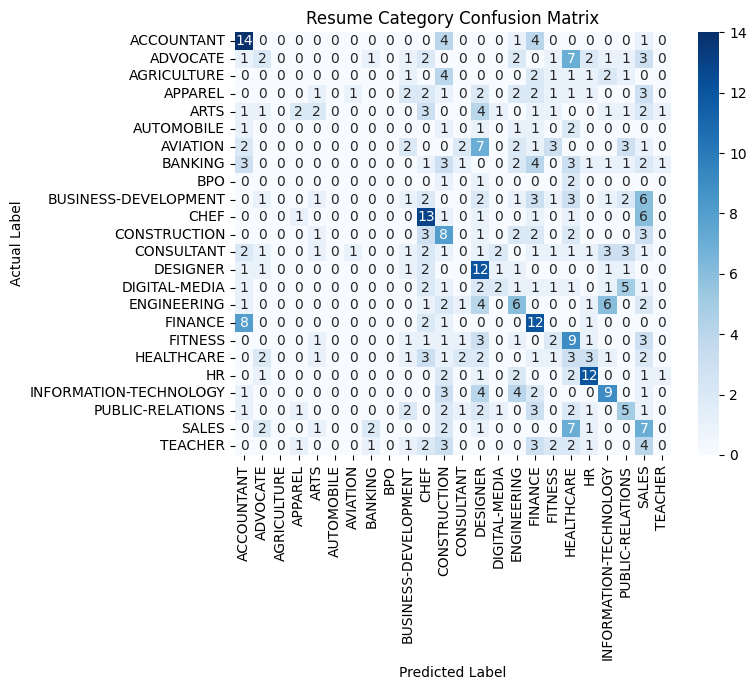

In [56]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test_encoded, y_pred)

plt.figure(figsize=(8, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Resume Category Confusion Matrix")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [57]:
import pandas as pd

prediction_counts = pd.Series(y_pred).value_counts().sort_index()

prediction_distribution = pd.DataFrame({
    "Class": range(len(label_encoder.classes_)),
    "Category": label_encoder.classes_,
    "Predicted_Count": prediction_counts.reindex(
        range(len(label_encoder.classes_)),
        fill_value=0
).values
})

print(prediction_distribution)

    Class                Category  Predicted_Count
0       0              ACCOUNTANT               37
1       1                ADVOCATE               11
2       2             AGRICULTURE                0
3       3                 APPAREL                5
4       4                    ARTS                9
5       5              AUTOMOBILE                0
6       6                AVIATION                2
7       7                 BANKING                4
8       8                     BPO                0
9       9    BUSINESS-DEVELOPMENT               14
10     10                    CHEF               41
11     11            CONSTRUCTION               42
12     12              CONSULTANT                8
13     13                DESIGNER               51
14     14           DIGITAL-MEDIA                7
15     15             ENGINEERING               28
16     16                 FINANCE               44
17     17                 FITNESS               15
18     18              HEALTHCA

In [58]:
from sklearn.linear_model import LogisticRegression
logistic_model = LogisticRegression(
    max_iter=1000,
    C=1.0,
    solver="lbfgs"
)
logistic_model.fit(
    X_train,
    y_train_encoded
)
print("Logistic Regression training completed.")

Logistic Regression training completed.


In [59]:
lr_test_accuracy = logistic_model.score(
    X_test,
    y_test_encoded
)

print("Logistic Regression Test Accuracy:", lr_test_accuracy)

Logistic Regression Test Accuracy: 0.6579476861167002


In [60]:
from sklearn.metrics import classification_report

y_pred_lr = logistic_model.predict(X_test)

print(classification_report(
    y_test_encoded,
    y_pred_lr,
    target_names=label_encoder.classes_,
    zero_division=0
))

                        precision    recall  f1-score   support

            ACCOUNTANT       0.57      0.83      0.68        24
              ADVOCATE       0.38      0.58      0.46        24
           AGRICULTURE       1.00      0.38      0.56        13
               APPAREL       0.60      0.16      0.25        19
                  ARTS       0.50      0.38      0.43        21
            AUTOMOBILE       0.00      0.00      0.00         7
              AVIATION       0.81      0.74      0.77        23
               BANKING       0.83      0.65      0.73        23
                   BPO       0.00      0.00      0.00         4
  BUSINESS-DEVELOPMENT       0.55      0.92      0.69        24
                  CHEF       0.85      0.71      0.77        24
          CONSTRUCTION       0.85      0.77      0.81        22
            CONSULTANT       0.45      0.22      0.29        23
              DESIGNER       0.84      0.76      0.80        21
         DIGITAL-MEDIA       0.71      

In [61]:
class_weight="balanced"
from sklearn.linear_model import LogisticRegression

logistic_balanced = LogisticRegression(
    max_iter=1000,
    C=1.0,
    solver="lbfgs",
    class_weight="balanced"
)

logistic_balanced.fit(
    X_train,
    y_train_encoded
)

print("Balanced Logistic Regression training completed.")

Balanced Logistic Regression training completed.


In [62]:
y_pred_balanced = logistic_balanced.predict(X_test)

balanced_accuracy = logistic_balanced.score(
    X_test,
    y_test_encoded
)

print("Balanced Logistic Regression Test Accuracy:", balanced_accuracy)

Balanced Logistic Regression Test Accuracy: 0.670020120724346


In [63]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test_encoded,
    y_pred_balanced,
    target_names=label_encoder.classes_,
    zero_division=0
))

                        precision    recall  f1-score   support

            ACCOUNTANT       0.56      0.83      0.67        24
              ADVOCATE       0.48      0.50      0.49        24
           AGRICULTURE       0.58      0.54      0.56        13
               APPAREL       0.44      0.21      0.29        19
                  ARTS       0.47      0.38      0.42        21
            AUTOMOBILE       0.50      0.57      0.53         7
              AVIATION       0.84      0.70      0.76        23
               BANKING       0.88      0.65      0.75        23
                   BPO       0.50      0.50      0.50         4
  BUSINESS-DEVELOPMENT       0.58      0.88      0.70        24
                  CHEF       0.85      0.71      0.77        24
          CONSTRUCTION       0.82      0.82      0.82        22
            CONSULTANT       0.50      0.22      0.30        23
              DESIGNER       0.89      0.76      0.82        21
         DIGITAL-MEDIA       0.73      

In [64]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

C_values = [0.1, 0.5, 1, 2, 5]

results = []

for c in C_values:

    model = LogisticRegression(
        max_iter=1000,
        C=c,
        solver="lbfgs",
        class_weight="balanced"
    )

    model.fit(X_train, y_train_encoded)

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test_encoded, predictions)

    macro_f1 = f1_score(
        y_test_encoded,
        predictions,
        average="macro"
    )

    weighted_f1 = f1_score(
        y_test_encoded,
        predictions,
        average="weighted"
    )

    results.append([
        c,
        accuracy,
        macro_f1,
        weighted_f1
    ])

results

[[0.1, 0.607645875251509, 0.5496085455593414, 0.5741129816977331],
 [0.5, 0.6498993963782697, 0.624628590576035, 0.6344686080050137],
 [1, 0.670020120724346, 0.6475884847616168, 0.6618808300842852],
 [2, 0.6740442655935613, 0.644119171383577, 0.666339548085021],
 [5, 0.6841046277665996, 0.6426738955149675, 0.6771851495599396]]

In [65]:
import pandas as pd

results_df = pd.DataFrame(
    results,
    columns=["C", "Accuracy", "Macro_F1", "Weighted_F1"]
)

print(results_df)

     C  Accuracy  Macro_F1  Weighted_F1
0  0.1  0.607646  0.549609     0.574113
1  0.5  0.649899  0.624629     0.634469
2  1.0  0.670020  0.647588     0.661881
3  2.0  0.674044  0.644119     0.666340
4  5.0  0.684105  0.642674     0.677185


In [66]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_bigram = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_train_tfidf_bigram = tfidf_bigram.fit_transform(X_train_text)
X_test_tfidf_bigram = tfidf_bigram.transform(X_test_text)

print("Training shape:", X_train_tfidf_bigram.shape)
print("Testing shape:", X_test_tfidf_bigram.shape)

Training shape: (1984, 10000)
Testing shape: (497, 10000)


In [67]:
from sklearn.linear_model import LogisticRegression

logistic_bigram = LogisticRegression(
    max_iter=1000,
    C=5,
    solver="lbfgs",
    class_weight="balanced"
)

logistic_bigram.fit(
    X_train_tfidf_bigram,
    y_train_encoded
)

print("Bigram Logistic Regression training completed.")

Bigram Logistic Regression training completed.


In [68]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

y_pred_bigram = logistic_bigram.predict(
    X_test_tfidf_bigram
)

accuracy_bigram = accuracy_score(
    y_test_encoded,
    y_pred_bigram
)

macro_f1_bigram = f1_score(
    y_test_encoded,
    y_pred_bigram,
    average="macro"
)

weighted_f1_bigram = f1_score(
    y_test_encoded,
    y_pred_bigram,
    average="weighted"
)

print("Bigram Accuracy:", accuracy_bigram)
print("Bigram Macro F1:", macro_f1_bigram)
print("Bigram Weighted F1:", weighted_f1_bigram)

Bigram Accuracy: 0.6639839034205232
Bigram Macro F1: 0.6245299715358206
Bigram Weighted F1: 0.6519466953753909


In [69]:
print(classification_report(
    y_test_encoded,
    y_pred_bigram,
    target_names=label_encoder.classes_,
    zero_division=0
))

                        precision    recall  f1-score   support

            ACCOUNTANT       0.57      0.83      0.68        24
              ADVOCATE       0.41      0.50      0.45        24
           AGRICULTURE       0.70      0.54      0.61        13
               APPAREL       0.50      0.21      0.30        19
                  ARTS       0.43      0.29      0.34        21
            AUTOMOBILE       1.00      0.43      0.60         7
              AVIATION       0.90      0.78      0.84        23
               BANKING       0.80      0.70      0.74        23
                   BPO       0.00      0.00      0.00         4
  BUSINESS-DEVELOPMENT       0.62      0.88      0.72        24
                  CHEF       0.84      0.67      0.74        24
          CONSTRUCTION       0.73      0.73      0.73        22
            CONSULTANT       0.67      0.26      0.38        23
              DESIGNER       0.86      0.86      0.86        21
         DIGITAL-MEDIA       0.79      

In [70]:
from sklearn.feature_extraction.text import TfidfVectorizer

final_tfidf = TfidfVectorizer(
    max_features=5000
)

X_train_final = final_tfidf.fit_transform(X_train_text)
X_test_final = final_tfidf.transform(X_test_text)

print("Train:", X_train_final.shape)
print("Test:", X_test_final.shape)

Train: (1984, 5000)
Test: (497, 5000)


In [71]:
from sklearn.linear_model import LogisticRegression

final_model = LogisticRegression(
    C=5,
    class_weight="balanced",
    max_iter=1000,
    solver="lbfgs"
)

final_model.fit(
    X_train_final,
    y_train_encoded
)

print("Final model trained successfully.")

Final model trained successfully.


In [72]:
final_accuracy = final_model.score(
    X_test_final,
    y_test_encoded
)

print("Final Test Accuracy:", final_accuracy)

Final Test Accuracy: 0.6740442655935613


In [73]:
import joblib

joblib.dump(final_model, "resume_classifier.pkl")
joblib.dump(final_tfidf, "resume_tfidf.pkl")
joblib.dump(label_encoder, "resume_label_encoder.pkl")

print("All 3 files saved successfully!")

All 3 files saved successfully!


In [74]:
import os

print(os.path.exists("resume_classifier.pkl"))
print(os.path.exists("resume_tfidf.pkl"))
print(os.path.exists("resume_label_encoder.pkl"))

True
True
True


# -------------Resume Screening Tool-----------

In [75]:
import joblib

# Load saved components
model = joblib.load("resume_classifier.pkl")
tfidf = joblib.load("resume_tfidf.pkl")
label_encoder = joblib.load("resume_label_encoder.pkl")

print("Models loaded successfully!")

Models loaded successfully!


In [85]:
def predict_resume_category(resume_text):
    
    # Convert text into TF-IDF features
    resume_vector = tfidf.transform([resume_text])
    
    # Predict class
    prediction = model.predict(resume_vector)[0]
    
    # Convert encoded class to category name
    category = label_encoder.inverse_transform([prediction])[0]
    
    # Get prediction probabilities
    probabilities = model.predict_proba(resume_vector)[0]
    
    # Get top 3 predictions
    top_indices = probabilities.argsort()[-3:][::-1]
    
    top_predictions = []
    
    for index in top_indices:
        category_name = label_encoder.inverse_transform([index])[0]
        confidence = probabilities[index] * 100
        
        top_predictions.append(
            (category_name, confidence)
        )
    
    return category, top_predictions

In [87]:
sample_resume = """
Python Developer with experience in Python, Pandas, NumPy,
Machine Learning, SQL, Scikit-learn, data analysis and
building predictive models.
"""

category, top_predictions = predict_resume_category(sample_resume)

print("Predicted Category:", category)

print("\nTop 3 Predictions:")
for category, confidence in top_predictions:
    print(f"{category}: {confidence:.2f}%")

Predicted Category: CONSULTANT

Top 3 Predictions:
CONSULTANT: 14.14%
ENGINEERING: 10.32%
AUTOMOBILE: 6.72%


In [88]:
from PyPDF2 import PdfReader
from docx import Document
import os

def extract_resume_text(file_path):

    extension = os.path.splitext(file_path)[1].lower()

    # PDF
    if extension == ".pdf":

        reader = PdfReader(file_path)

        text = ""

        for page in reader.pages:
            page_text = page.extract_text()

            if page_text:
                text += page_text + "\n"

        return text

    # DOCX
    elif extension == ".docx":

        document = Document(file_path)

        text = "\n".join(
            paragraph.text
            for paragraph in document.paragraphs
        )

        return text

    else:
        raise ValueError(
            "Unsupported file format. Please upload PDF or DOCX."
        )

In [79]:
file_path = r"C:\Users\S. Umredkar\Desktop\Data Science IPCS Global\Resume screening Tool\Dataset\data\data\ENGINEERING\10030015.pdf"

resume_text = extract_resume_text(file_path)

print(resume_text[:2000])

ENGINEERING LAB TECHNICIAN
Career Focus
My main objective in seeking employment with Triumph Actuation Systems Inc. is to work in a professional atmosphere where I can utilize my
skills and continue to gain experience in the aerospace industry to advance in my career.
Professional Experience
Engineering Lab Technician
 
Oct 2016
 
to 
Current
 
Company Name
 
ï¼​ 
City
 
, 
State
Responsible for testing various seat structures to meet specific certification requirements. Â 
Maintain and calibrate test instruments to ensure testing capabilities are maintained.
Ensure data is captured and recorded correctly for certification test reports.
Duties also dynamic test set-up and static suite testing. 
Engineering Lab Technician, Sr. Specialist
 
Apr 2012
 
to 
Oct 2016
 
Company Name
 
ï¼​ 
City
 
, 
State
Utilized skills learned from LabView Course 1 training to construct and maintain LabView VI programs.
Responsible for fabricating and maintaining hydraulic/electrical test equipment to comp

In [80]:
def screen_resume(file_path):

    # 1. Extract text from PDF/DOCX
    resume_text = extract_resume_text(file_path)

    if not resume_text.strip():
        raise ValueError("Could not extract any text from this resume.")

    # 2. Convert resume text into TF-IDF
    resume_vector = tfidf.transform([resume_text])

    # 3. Predict category
    prediction = model.predict(resume_vector)[0]

    category = label_encoder.inverse_transform([prediction])[0]

    # 4. Get probabilities
    probabilities = model.predict_proba(resume_vector)[0]

    # 5. Get top 3 predictions
    top_indices = probabilities.argsort()[-3:][::-1]

    top_predictions = []

    for index in top_indices:
        category_name = label_encoder.inverse_transform([index])[0]
        confidence = probabilities[index] * 100

        top_predictions.append({
            "category": category_name,
            "confidence": round(confidence, 2)
        })

    return {
        "predicted_category": category,
        "top_predictions": top_predictions,
        "extracted_text": resume_text
    }

In [81]:
file_path = r"C:\Users\S. Umredkar\Desktop\Data Science IPCS Global\Resume screening Tool\Dataset\data\data\ENGINEERING\11981094.pdf"

result = screen_resume(file_path)

print("Predicted Category:")
print(result["predicted_category"])

print("\nTop 3 Predictions:")

for prediction in result["top_predictions"]:
    print(
        prediction["category"],
        "→",
        prediction["confidence"],
        "%"
    )

Predicted Category:
ENGINEERING

Top 3 Predictions:
ENGINEERING → 77.53 %
DIGITAL-MEDIA → 4.28 %
CONSULTANT → 3.13 %


In [89]:
import joblib

model = joblib.load("resume_classifier.pkl")
tfidf = joblib.load("resume_tfidf.pkl")
label_encoder = joblib.load("resume_label_encoder.pkl")

In [90]:
import streamlit as st
import joblib
import os

from PyPDF2 import PdfReader
from docx import Document


# -----------------------------
# Load trained model
# -----------------------------

model = joblib.load("resume_classifier.pkl")
tfidf = joblib.load("resume_tfidf.pkl")
label_encoder = joblib.load("resume_label_encoder.pkl")


# -----------------------------
# Extract text from resume
# -----------------------------

def extract_resume_text(uploaded_file):

    file_extension = os.path.splitext(uploaded_file.name)[1].lower()

    if file_extension == ".pdf":

        reader = PdfReader(uploaded_file)

        text = ""

        for page in reader.pages:
            page_text = page.extract_text()

            if page_text:
                text += page_text + "\n"

        return text

    elif file_extension == ".docx":

        document = Document(uploaded_file)

        text = "\n".join(
            paragraph.text
            for paragraph in document.paragraphs
        )

        return text

    else:
        raise ValueError(
            "Only PDF and DOCX files are supported."
        )


# -----------------------------
# Page
# -----------------------------

st.set_page_config(
    page_title="Resume Screening Tool",
    page_icon="📄",
    layout="centered"
)

st.title("📄 Resume Screening Tool")

st.write(
    "Upload a resume to predict its most suitable career category."
)

uploaded_file = st.file_uploader(
    "Upload Resume",
    type=["pdf", "docx"]
)


# -----------------------------
# Prediction
# -----------------------------

if uploaded_file is not None:

    st.success(f"Uploaded: {uploaded_file.name}")

    if st.button("🔍 Screen Resume"):

        try:

            resume_text = extract_resume_text(uploaded_file)

            if not resume_text.strip():
                st.error(
                    "Could not extract text from this resume."
                )

            else:

                # TF-IDF transformation
                resume_vector = tfidf.transform(
                    [resume_text]
                )

                # Prediction
                prediction = model.predict(
                    resume_vector
                )[0]

                category = label_encoder.inverse_transform(
                    [prediction]
                )[0]

                # Probabilities
                probabilities = model.predict_proba(
                    resume_vector
                )[0]

                # Top 3
                top_indices = probabilities.argsort()[-3:][::-1]

                st.subheader("🎯 Predicted Category")

                st.success(category)

                st.subheader("📊 Top 3 Predictions")

                for index in top_indices:

                    category_name = label_encoder.inverse_transform(
                        [index]
                    )[0]

                    confidence = probabilities[index] * 100

                    st.write(
                        f"**{category_name}** — "
                        f"{confidence:.2f}%"
                    )

                    st.progress(
                        float(probabilities[index])
                    )

        except Exception as e:

            st.error(f"Error: {e}")

2026-08-12 17:00:32.659 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-12 17:00:32.660 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-12 17:00:32.663 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-12 17:00:32.663 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-12 17:00:32.663 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-12 17:00:32.663 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-12 17:00:32.663 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-08-12 17:00:32.663 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

In [91]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


def calculate_relevance(resume_text, job_description):
    """
    Calculate how relevant a resume is to a job description
    using TF-IDF cosine similarity.
    """

    documents = [
        resume_text,
        job_description
    ]

    vectorizer = TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2)
    )

    vectors = vectorizer.fit_transform(documents)

    similarity = cosine_similarity(
        vectors[0:1],
        vectors[1:2]
    )[0][0]

    relevance_score = similarity * 100

    return round(relevance_score, 2)

In [92]:
job_description = """
We are looking for a Data Scientist with experience in Python,
SQL, machine learning, data analysis, Pandas, NumPy,
Scikit-learn and statistical modeling.

The candidate should be able to build predictive models,
analyze datasets, create visualizations and communicate
data-driven insights.
"""

score = calculate_relevance(
    resume_text,
    job_description
)

print("Resume-JD Relevance Score:", score, "%")

Resume-JD Relevance Score: 1.17 %


In [93]:
data_science_jd = """
Data Scientist required with Python, SQL, machine learning,
Pandas, NumPy, Scikit-learn, statistics, data analysis,
predictive modeling and data visualization.
"""

score_ds = calculate_relevance(
    resume_text,
    data_science_jd
)

print("Data Science Match:", score_ds, "%")

Data Science Match: 0.74 %


In [94]:
automobile_jd = """
Automobile engineer required with experience in vehicle design,
automotive systems, mechanical engineering, CAD, manufacturing,
vehicle maintenance and automotive production.
"""

score_auto = calculate_relevance(
    resume_text,
    automobile_jd
)

print("Automobile Match:", score_auto, "%")

Automobile Match: 5.35 %
